#Predicting energy of the au clusters with Gaussian regression

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
%pip install -q kagglehub
import kagglehub as khub
from pathlib import Path 


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
path = Path(khub.dataset_download("leewevml/energy-prediction-of-three-dimensional-clusters"))

In [8]:
files = sorted(p for p in path.rglob("*") if p.is_file())
print(path)
print(len(files), "files")
for f in files[:20]:
    print(f.relative_to(path))

/Users/mateolondono/.cache/kagglehub/datasets/leewevml/energy-prediction-of-three-dimensional-clusters/versions/3
4750 files
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/0.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/1.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/10.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/100.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/101.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/102.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/103.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/104.xyz
Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/105.xyz
Coordinates and 

In [28]:
# Visualizing one of the files
f = files[100]
print(f)
text = f.read_text()
print(text)

/Users/mateolondono/.cache/kagglehub/datasets/leewevml/energy-prediction-of-three-dimensional-clusters/versions/3/Coordinates and energies of clusters/Coordinates and energies of clusters/Au20_OPT_1000/19.xyz
20
-1549.039125
Au       1.30270910       1.30270905       1.39198420 
Au      -1.30270903      -1.30270908       1.39198417 
Au      -1.30270897       1.30270898       1.39198401 
Au       1.30270899      -1.30270898       1.39198403 
Au       2.94966372       2.94966372      -2.56450597 
Au      -2.94966372      -2.94966372      -2.56450596 
Au      -2.94966370       2.94966370      -2.56450594 
Au       2.94966371      -2.94966371      -2.56450596 
Au       2.94995956       2.94995956       2.56439540 
Au      -2.94995957      -2.94995957       2.56439541 
Au      -2.94995958       2.94995958       2.56439543 
Au       2.94995958      -2.94995958       2.56439542 
Au      -2.88038981      -2.88038981      -0.00008918 
Au       2.88038981       2.88038981      -0.00008917 
Au   

In [59]:
print(type(f))

<class 'pathlib.PosixPath'>


In [96]:
# Extract attomic coordinates and energy from files:
def extractor(file):

    try:
     type(file)=='pathlib.PosixPath'
    except NameError:
      print("Non path variable")

    lines = file.read_text().splitlines()

    n_atoms = int(lines[0])
    energy = float(lines[1])

    coords = np.array([
        list(map(float, line.split()[1:4]))
        for line in lines[2:2+n_atoms]
    ])

    return coords, energy



# Define the coulomb matrix
def C_matrix(f, Z):
    coords, energy = extractor(f)
    """ We define the Coulomb matrix for each cluster geometry"""

    N = len(coords)
    C_mat = np.zeros((N, N))

    # Diagonal elements
    for i in range(N):
        C_mat[i, i] = 0.5 * Z**2.4

    # Off-diagonal elements
    for i in range(N):
        for j in range(i + 1, N):
            r_ij = np.linalg.norm(coords[i] - coords[j])
            
            C_mat[i, j] = Z**2 / r_ij
            C_mat[j, i] = C_mat[i, j]

    # Eigenvalues
    eig = np.linalg.eigvalsh(C_mat)

    return C_mat, eig, energy


In [ ]:
%pip install -q scikit-learn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [105]:
#Save only data for Au
files_au = [x for x in files if "Au" in str(x)]

#Save the eigenvalue vectors and energies of each cluster
M_eig = np.zeros((1000,20),dtype=float)
Energies = np.zeros(1000)
for index,file in enumerate(files_au):
    C_m,eig,energy = C_matrix(file, 79)
    M_eig[index,:] = eig                   
    Energies[index]= energy

#Confirm sizes 
print(np.shape(M_eig))
print(np.shape(Energies))

#save as data_sets for exploring latter with pandas
np.savetxt("M_eig",M_eig)
np.savetxt("Energies", Energies)

(1000, 20)
(1000,)


In [127]:
# Read the data again as a dataset with pandas
X = pd.read_csv("../Au_clusters/M_eig",header=None,delim_whitespace=True)
Y = pd.read_csv("../Au_clusters/Energies",header=None,delim_whitespace=True)

#Verify is there are null values
Y.columns=['Au']
Y.sort_values(by=['Au'],ascending=True)

,Au
279,-1557.209460
782,-1556.299794
241,-1555.942377
946,-1555.942376
926,-1555.942374
...,...
594,-1538.870624
897,-1538.497324
754,-1530.908363
998,0.000000


In [128]:
#Get rid of null values
X.drop(index=998,inplace=True,axis=0)
Y.drop(index=998,inplace=True,axis=0)

X.drop(index=999,inplace=True,axis=0)
Y.drop(index=999,inplace=True,axis=0)
X.reset_index(drop=True,inplace=True)
Y.reset_index(drop=True,inplace=True)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


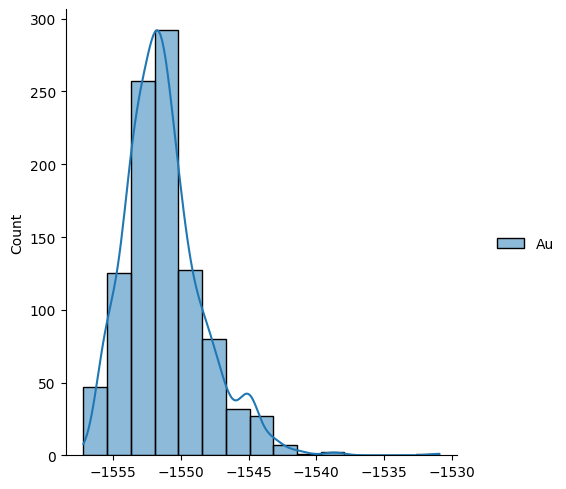

In [129]:
sns.displot(Y,bins=15,kde=True,label = 'count')


In [137]:
# Training the model and testing the model. 
X_np = X.to_numpy()
Y_np = Y["Au"].to_numpy()

X_train, X_test, Y_train, Y_test = train_test_split(X_np,Y_np,test_size=0.2,random_state=42)
print("train:", X_train.shape, "test:", X_test.shape)

print(X_train[5][:])

train: (798, 20) test: (200, 20)
[14752.64613076 14788.7486258  14788.74995771 14863.22382093
 14879.5233325  14879.53103506 14950.55545632 15102.27780816
 15171.98172759 15171.99690668 15207.43196283 15695.80221702
 16082.45519208 17355.28466628 17419.57203391 17419.62868951
 20992.23288083 20992.3158589  21307.27618675 46526.79369233]


In [ ]:
# Scaling and defining kernel

kernel = (ConstantKernel(1.0, (1e-3, 1e3))
          * RBF(length_scale=np.ones(X_np.shape[1]), length_scale_bounds=(1e-2, 1e3))
          + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-8, 1e1)))

model = Pipeline([
    ("scaler", StandardScaler()),
    ("gpr", GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                                     n_restarts_optimizer=3, random_state=42)),
])



NotFittedError: This StandardScaler instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.